In [18]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

In [19]:
# Read the data
df = pd.read_csv("Salary_Data.csv")
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [ ]:
# Select input and Target as X and y
X = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [21]:
# split the data and keep test_size as 0.3 and random_state = 0
# If i run the model and if i want run it again then we write random state and so it will select same data for
# training and testing data again
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)


In [22]:
# import linear regression, make instance and fit the data
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
# Check for the slope and y-intercept
print(reg.coef_)
print(reg.intercept_)

[9360.26128619]
26777.391341197625


In [ ]:

print(reg.predict([[6.7]]))

[89491.1419587]


In [32]:
# predict the test set result y_pred
y_pred = reg.predict(X_test)
y_pred

array([ 40817.78327049, 123188.08258899,  65154.46261459,  63282.41035735,
       115699.87356004, 108211.66453108, 116635.89968866,  64218.43648597,
        76386.77615802])

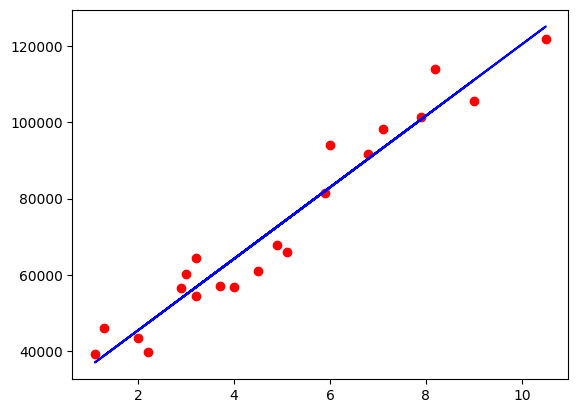

In [27]:
# Visualising the training set result
plt.scatter(X_train, y_train, color = "red")
plt.plot(X_train, reg.predict(X_train), color = 'blue')

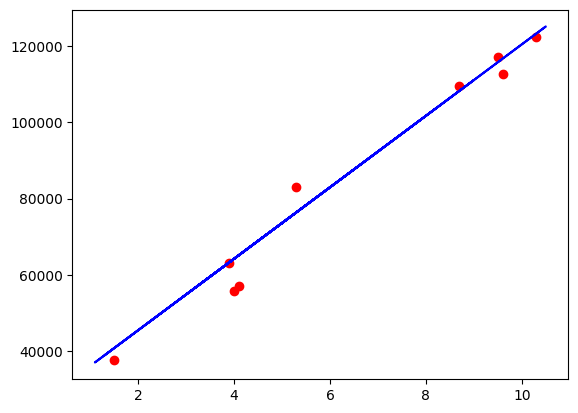

In [28]:
# Visualising the testing set result
plt.scatter(X_test, y_test, color = "red")
plt.plot(X_train, reg.predict(X_train), color = 'blue')

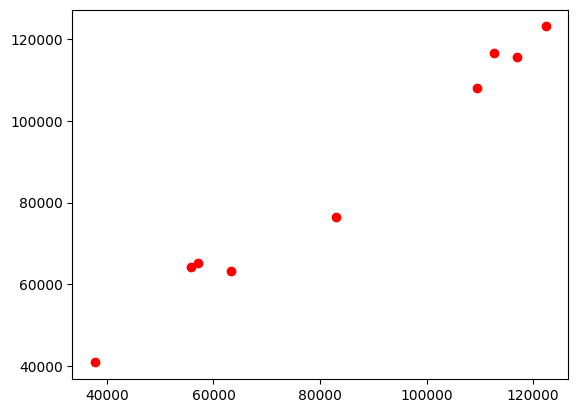

In [61]:
plt.scatter(y_test, y_pred, color = "red")


In [34]:
# evaluation in sklearn.metrics mean_absoloute_error, mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred)
RMSE = np.sqrt(MSE)

In [ ]:
# Model Evaluation

print(MAE)
print(MSE)
print(R2)
print(RMSE)

3737.417861878896
23370078.800832972
0.9740993407213511
4834.260936361728


In [37]:
comp_df = pd.DataFrame({'Actual Salary (y_test)': y_test, 'Predicted Salary (y_pred)': y_pred})
comp_df

,Actual Salary (y_test),Predicted Salary (y_pred)
0,37731.0,40817.783270
1,122391.0,123188.082589
2,57081.0,65154.462615
3,63218.0,63282.410357
4,116969.0,115699.873560
5,109431.0,108211.664531
6,112635.0,116635.899689
7,55794.0,64218.436486
8,83088.0,76386.776158


In [38]:
mean_x = X_train.mean()
mean_y = y_train.mean()

In [43]:
upp = 0
for i in range(len(X_train)):
    upp += (X_train[i]-mean_x)*(y_train[i]-mean_y)

print(upp[0])

1288462.2523809525


In [44]:
den = 0
for i in range(len(X_train)):
    den += (X_train[i]-mean_x)**2

print(den[0])

137.65238095238092


In [49]:
slope = upp/den
print(slope[0])

9360.261286193658


In [50]:
y_intercept = mean_y - (mean_x*slope)
print(y_intercept[0])

26777.39134119761


In [47]:
reg.coef_

array([9360.26128619])